In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load datasets
customers = pd.read_csv("../data/synthetic/customers.csv")
orders = pd.read_csv("../data/synthetic/orders.csv")

# Convert date columns
orders["order_date"] = pd.to_datetime(orders["order_date"])
customers["signup_date"] = pd.to_datetime(customers["signup_date"])

print("Customer Intelligence Started!")
print("Customers:", customers.shape)
print("Orders:", orders.shape)


Customer Intelligence Started!
Customers: (500, 6)
Orders: (2043, 8)


In [2]:

# Use delivered orders for purchase analysis
delivered_orders = orders[
    orders["order_status"] == "Delivered"
].copy()

# Reference date for this analysis
analysis_date = orders["order_date"].max() + pd.Timedelta(days=1)

# Calculate RFM metrics
rfm = delivered_orders.groupby("customer_id").agg(
    last_purchase=("order_date", "max"),
    frequency=("order_id", "nunique"),
    monetary=("order_value", "sum")
).reset_index()

# Calculate recency in days
rfm["recency"] = (
    analysis_date - rfm["last_purchase"]
).dt.days

# Keep all customers, including those without delivered orders
rfm = customers[["customer_id"]].merge(
    rfm,
    on="customer_id",
    how="left"
)

# Customers without delivered orders have zero frequency and spending
rfm["frequency"] = rfm["frequency"].fillna(0).astype(int)
rfm["monetary"] = rfm["monetary"].fillna(0)

print("RFM Analysis Completed!")
display(rfm.head(10))


RFM Analysis Completed!


,customer_id,last_purchase,frequency,monetary,recency
0,CUST0001,2026-11-02 16:55:00,2,1186.36,8.0
1,CUST0002,2026-08-05 08:14:00,4,4493.55,97.0
2,CUST0003,2026-07-01 20:39:00,1,517.74,132.0
3,CUST0004,2026-09-28 02:08:00,6,12560.95,43.0
4,CUST0005,2026-11-07 21:54:00,9,20284.83,3.0
5,CUST0006,2026-09-22 21:15:00,3,6354.00,49.0
6,CUST0007,2026-07-28 03:41:00,4,5797.39,105.0
7,CUST0008,2026-11-02 12:41:00,6,11550.33,8.0
8,CUST0009,2026-11-05 07:35:00,2,2771.65,5.0
9,CUST0010,2026-09-09 17:36:00,4,4736.51,62.0


In [3]:
print("RFM Shape:", rfm.shape)

print("\nMissing Values:")
print(rfm.isnull().sum())

print("\nRFM Statistics:")
display(rfm[["recency", "frequency", "monetary"]].describe())

RFM Shape: (500, 5)

Missing Values:
customer_id       0
last_purchase    18
frequency         0
monetary          0
recency          18
dtype: int64

RFM Statistics:


,recency,frequency,monetary
count,482.000000,500.00000,500.000000
mean,42.711618,3.42600,5341.861380
std,41.282076,2.30024,4014.728996
min,1.000000,0.00000,0.000000
25%,9.000000,2.00000,2352.457500
50%,29.000000,3.00000,4503.610000
75%,63.000000,5.00000,7579.525000
max,181.000000,12.00000,23696.910000


In [4]:
rfm.head(10)

,customer_id,last_purchase,frequency,monetary,recency
0,CUST0001,2026-11-02 16:55:00,2,1186.36,8.0
1,CUST0002,2026-08-05 08:14:00,4,4493.55,97.0
2,CUST0003,2026-07-01 20:39:00,1,517.74,132.0
3,CUST0004,2026-09-28 02:08:00,6,12560.95,43.0
4,CUST0005,2026-11-07 21:54:00,9,20284.83,3.0
5,CUST0006,2026-09-22 21:15:00,3,6354.00,49.0
6,CUST0007,2026-07-28 03:41:00,4,5797.39,105.0
7,CUST0008,2026-11-02 12:41:00,6,11550.33,8.0
8,CUST0009,2026-11-05 07:35:00,2,2771.65,5.0
9,CUST0010,2026-09-09 17:36:00,4,4736.51,62.0


In [5]:

# Create a copy
rfm_scored = rfm.copy()

# Customers without delivered purchases get the lowest score
rfm_scored["R_score"] = 1
rfm_scored["F_score"] = 1
rfm_scored["M_score"] = 1

# Score customers who have delivered purchases
active = rfm_scored["frequency"] > 0

# Recency: fewer days means a higher score
rfm_scored.loc[active, "R_score"] = pd.qcut(
    rfm_scored.loc[active, "recency"].rank(method="first"),
    5,
    labels=[5, 4, 3, 2, 1]
).astype(int)

# Frequency: more orders means a higher score
rfm_scored.loc[active, "F_score"] = pd.qcut(
    rfm_scored.loc[active, "frequency"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

# Monetary: more spending means a higher score
rfm_scored.loc[active, "M_score"] = pd.qcut(
    rfm_scored.loc[active, "monetary"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

# Combined RFM score
rfm_scored["RFM_score"] = (
    rfm_scored["R_score"].astype(str) +
    rfm_scored["F_score"].astype(str) +
    rfm_scored["M_score"].astype(str)
)

display(rfm_scored.head(10))


,customer_id,last_purchase,frequency,monetary,recency,R_score,F_score,M_score,RFM_score
0,CUST0001,2026-11-02 16:55:00,2,1186.36,8.0,5,2,1,521
1,CUST0002,2026-08-05 08:14:00,4,4493.55,97.0,1,3,3,133
2,CUST0003,2026-07-01 20:39:00,1,517.74,132.0,1,1,1,111
3,CUST0004,2026-09-28 02:08:00,6,12560.95,43.0,2,5,5,255
4,CUST0005,2026-11-07 21:54:00,9,20284.83,3.0,5,5,5,555
5,CUST0006,2026-09-22 21:15:00,3,6354.00,49.0,2,2,4,224
6,CUST0007,2026-07-28 03:41:00,4,5797.39,105.0,1,3,3,133
7,CUST0008,2026-11-02 12:41:00,6,11550.33,8.0,4,5,5,455
8,CUST0009,2026-11-05 07:35:00,2,2771.65,5.0,5,2,2,522
9,CUST0010,2026-09-09 17:36:00,4,4736.51,62.0,2,3,3,233


In [6]:
print(rfm_scored[
    ["R_score", "F_score", "M_score"]
].describe())

print("\nRFM Score Distribution:")
print(rfm_scored["RFM_score"].value_counts().head(10))

          R_score     F_score     M_score
count  500.000000  500.000000  500.000000
mean     2.928000    2.928000    2.928000
std      1.441865    1.441865    1.441865
min      1.000000    1.000000    1.000000
25%      2.000000    2.000000    2.000000
50%      3.000000    3.000000    3.000000
75%      4.000000    4.000000    4.000000
max      5.000000    5.000000    5.000000

RFM Score Distribution:
RFM_score
111    53
555    32
355    18
455    15
344    14
112    13
211    12
444    12
222    12
233    11
Name: count, dtype: int64


In [7]:

import numpy as np

conditions = [
    rfm_scored["frequency"] == 0,

    (rfm_scored["R_score"] >= 4) &
    (rfm_scored["F_score"] >= 4) &
    (rfm_scored["M_score"] >= 4),

    (rfm_scored["F_score"] >= 4) &
    (rfm_scored["R_score"] >= 3),

    (rfm_scored["R_score"] >= 4) &
    (rfm_scored["F_score"].between(2, 3)),

    (rfm_scored["R_score"] >= 4) &
    (rfm_scored["F_score"] == 1),

    (rfm_scored["R_score"] <= 2) &
    (rfm_scored["F_score"] >= 3),

    (rfm_scored["R_score"] <= 2) &
    (rfm_scored["F_score"] <= 2)
]

segments = [
    "No Delivered Purchase",
    "Champions",
    "Loyal Customers",
    "Potential Loyalists",
    "New Customers",
    "At Risk",
    "Hibernating"
]

rfm_scored["customer_segment"] = np.select(
    conditions,
    segments,
    default="Regular Customers"
)

display(
    rfm_scored[
        ["customer_id", "R_score", "F_score",
         "M_score", "customer_segment"]
    ].head(15)
)


,customer_id,R_score,F_score,M_score,customer_segment
0,CUST0001,5,2,1,Potential Loyalists
1,CUST0002,1,3,3,At Risk
2,CUST0003,1,1,1,Hibernating
3,CUST0004,2,5,5,At Risk
4,CUST0005,5,5,5,Champions
5,CUST0006,2,2,4,Hibernating
6,CUST0007,1,3,3,At Risk
7,CUST0008,4,5,5,Champions
8,CUST0009,5,2,2,Potential Loyalists
9,CUST0010,2,3,3,At Risk


In [8]:
segment_counts = rfm_scored[
    "customer_segment"
].value_counts()

print(segment_counts)

customer_segment
Hibernating              123
Champions                 86
Potential Loyalists       75
At Risk                   70
Loyal Customers           70
Regular Customers         47
No Delivered Purchase     18
New Customers             11
Name: count, dtype: int64


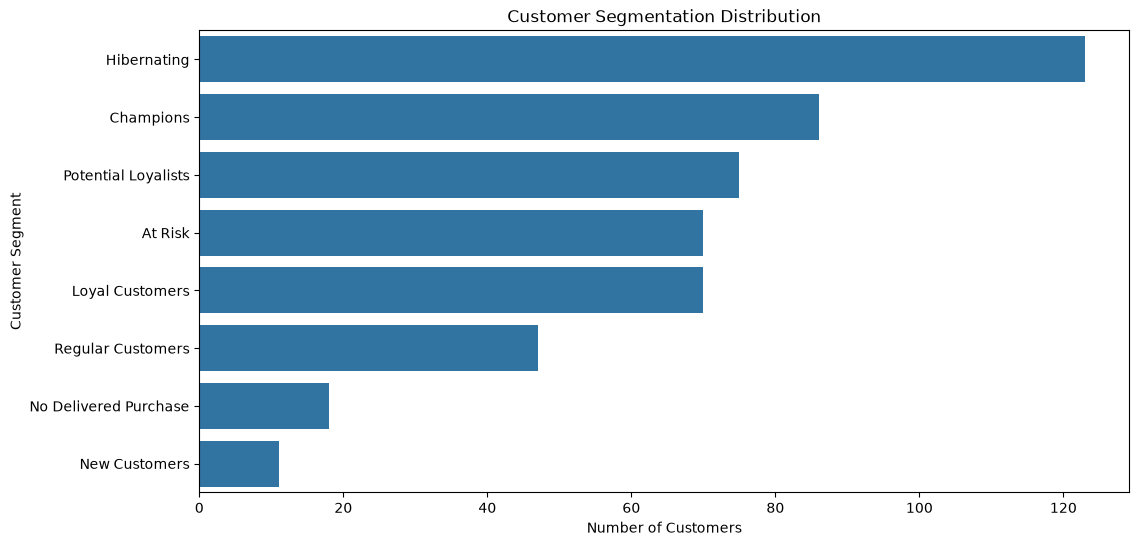

In [9]:
plt.figure(figsize=(12, 6))

sns.countplot(
    data=rfm_scored,
    y="customer_segment",
    order=segment_counts.index
)

plt.title("Customer Segmentation Distribution")
plt.xlabel("Number of Customers")
plt.ylabel("Customer Segment")

plt.show()

In [10]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

print("Machine Learning libraries loaded!")

Machine Learning libraries loaded!


In [11]:
# Create machine-learning dataset
kmeans_data = rfm_scored[
    ["customer_id", "recency", "frequency", "monetary"]
].copy()

# Handle customers without delivered purchases
max_recency = kmeans_data["recency"].max()

kmeans_data["recency"] = (
    kmeans_data["recency"].fillna(max_recency + 30)
)

# Reduce monetary-value skew
kmeans_data["monetary_log"] = np.log1p(
    kmeans_data["monetary"]
)

# Select features
features = kmeans_data[
    ["recency", "frequency", "monetary_log"]
]

display(features.head())

,recency,frequency,monetary_log
0,8.0,2,7.079488
1,97.0,4,8.410621
2,132.0,1,6.251403
3,43.0,6,9.438428
4,3.0,9,9.917678


In [12]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(features)

print("Feature scaling completed!")
print("Dataset shape:", X_scaled.shape)

Feature scaling completed!
Dataset shape: (500, 3)


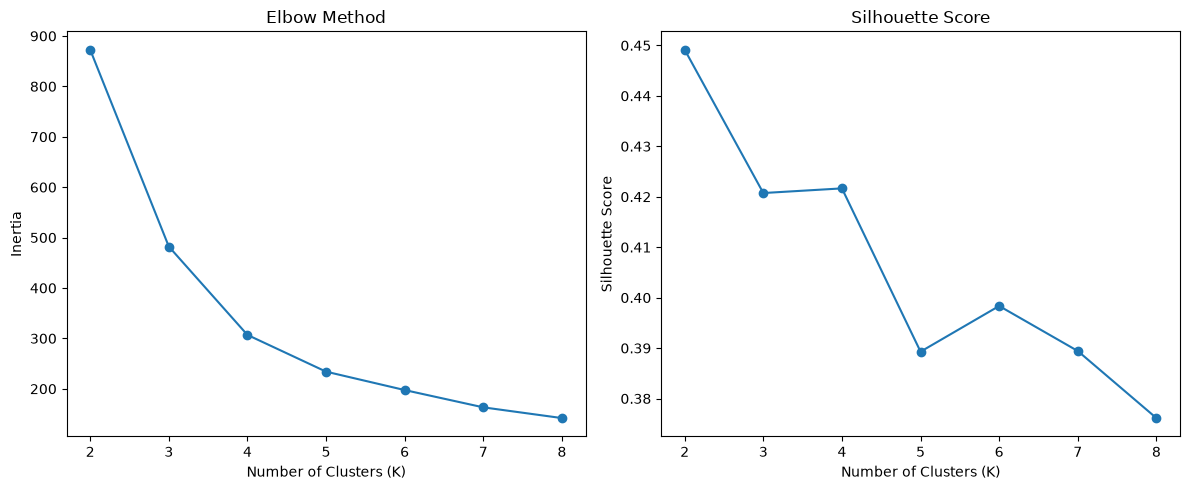

In [13]:
inertia_values = []
silhouette_values = []
k_values = range(2, 9)

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_scaled)

    inertia_values.append(model.inertia_)
    silhouette_values.append(
        silhouette_score(X_scaled, labels)
    )

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(list(k_values), inertia_values, marker="o")
plt.title("Elbow Method")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")

plt.subplot(1, 2, 2)
plt.plot(list(k_values), silhouette_values, marker="o")
plt.title("Silhouette Score")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")

plt.tight_layout()
plt.show()

In [14]:
# Display silhouette scores
for k, score in zip(k_values, silhouette_values):
    print(f"K = {k}, Silhouette Score = {score:.4f}")

# Select the K with the highest silhouette score
best_k = list(k_values)[
    np.argmax(silhouette_values)
]

print("\nBest K:", best_k)

K = 2, Silhouette Score = 0.4491
K = 3, Silhouette Score = 0.4207
K = 4, Silhouette Score = 0.4217
K = 5, Silhouette Score = 0.3893
K = 6, Silhouette Score = 0.3984
K = 7, Silhouette Score = 0.3894
K = 8, Silhouette Score = 0.3761

Best K: 2


In [15]:
# Create K-Means model
kmeans = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

# Train and predict clusters
cluster_labels = kmeans.fit_predict(X_scaled)

# Add cluster labels to customer data
kmeans_data["cluster"] = cluster_labels

print("K-Means training completed!")

K-Means training completed!


In [16]:
cluster_counts = kmeans_data["cluster"].value_counts().sort_index()

print("CUSTOMER CLUSTER DISTRIBUTION")
print(cluster_counts)

CUSTOMER CLUSTER DISTRIBUTION
cluster
0    136
1    364
Name: count, dtype: int64


In [17]:
cluster_analysis = kmeans_data.groupby("cluster").agg(
    customer_count=("customer_id", "count"),
    avg_recency=("recency", "mean"),
    avg_frequency=("frequency", "mean"),
    avg_monetary=("monetary", "mean")
).round(2)

display(cluster_analysis)

,customer_count,avg_recency,avg_frequency,avg_monetary
cluster,,,,
0,136,111.55,1.15,1780.01
1,364,25.31,4.27,6672.66


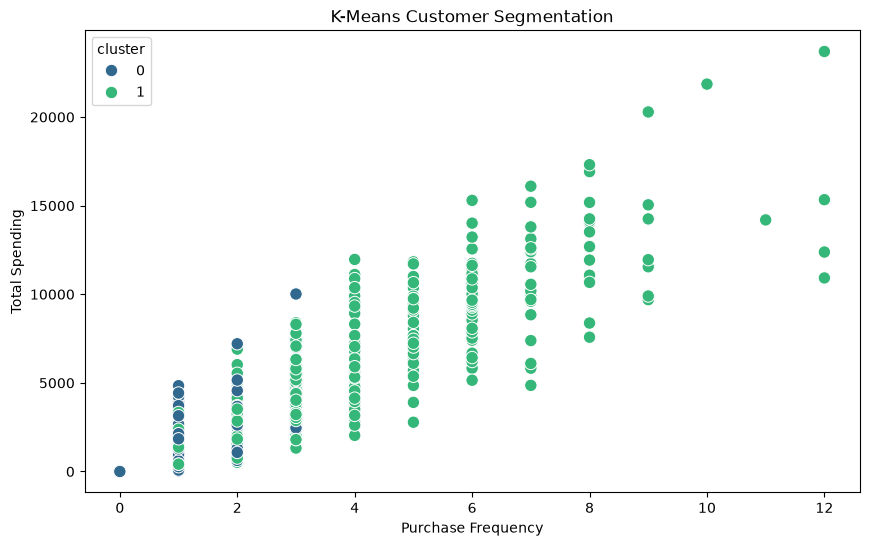

In [18]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=kmeans_data,
    x="frequency",
    y="monetary",
    hue="cluster",
    palette="viridis",
    s=80
)

plt.title("K-Means Customer Segmentation")
plt.xlabel("Purchase Frequency")
plt.ylabel("Total Spending")
plt.show()